# BAGFLOW — validação estatística das cinco variáveis aleatórias (M5)

Este notebook lê **exclusivamente dados exportados pelo Unity** (motor M3 real + geradores M2 reais, Unity 6000.6.7f1)
pelo exportador C# `SimulationExporter` / `ValidationBatchRunner` (ver `docs/M5_VALIDATION_EXPORT.md`).
Não há dados sintéticos: se a pasta `validation/data/unity` não existir, o notebook pára e indica como gerá-la.

| Conjunto | Origem | Uso |
|---|---|---|
| `example_seed42_n60` | 1 execução, parâmetros aprovados, seed 42 (formato `bags.csv`/`events.csv`/`config.json`) | integridade, fila, bloqueios de uma execução |
| `samples_n500` | 25 execuções × 500 malas, seeds 1000–1024 | amostras **brutas** Triangular, Exponencial, Normal truncada |
| `binomial_n60` | 2 000 execuções completas N=60, p=0,08, seeds 100000–101999 | Binomial (1 valor por execução) e Poisson (janelas fixas) |
| `scenario_*` | 300 execuções por cenário | comparação de cenários (não substituem os parâmetros aprovados) |

Fórmulas: `docs/MATH_MODELS.md`; implementação em `validation/bagflow_analysis.py` (testada em `test_analysis.py`).
Convenções: tempo em s, peso em kg; FDP/FMP teóricas sobrepostas a histogramas normalizados; FDPC empírica vs teórica;
erros-padrão de grandes amostras (z = (estimativa − teoria)/EP).

In [1]:
import os, sys, json, math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

HERE = os.path.abspath("") if os.path.basename(os.path.abspath("")) == "validation" else os.path.join(os.path.abspath(""), "validation")
sys.path.insert(0, HERE)
import bagflow_analysis as ba

DATA = os.path.join(HERE, "data", "unity")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)
if not os.path.isdir(os.path.join(DATA, "example_seed42_n60")):
    raise SystemExit("Sem exportações Unity em validation/data/unity. Gerar com: Unity > BAGFLOW > M5 > Generate validation data "
                     "(ou -executeMethod AirportBaggageSimulator.EditorTools.ValidationDataMenu.GenerateBatch).")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C_EMP, C_TH = "#3D8BFD", "#D9480F"
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, name + ".png"), dpi=130)
    plt.show()

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.0.3 | matplotlib 3.10.9


## 1. Dados e proveniência

In [2]:
example = ba.load_export(os.path.join(DATA, "example_seed42_n60"))
samples = ba.load_batch(os.path.join(DATA, "samples_n500"))
binom = ba.load_batch(os.path.join(DATA, "binomial_n60"))
scen_exp = ba.load_batch(os.path.join(DATA, "scenario_exponential_arrivals"))
scen_nob = ba.load_batch(os.path.join(DATA, "scenario_no_blockages"))

prov = pd.DataFrame([
    {"conjunto": "example_seed42_n60", "execuções": 1, "seeds": example.config["seed"], "N": example.parameters["BaggageCount"],
     "PRNG": example.config["prng_algorithm"], "versão app": example.config["app_version"], "exportado (UTC)": example.config["exported_utc"]},
    *[{"conjunto": b.meta["name"], "execuções": b.meta["runs"], "seeds": f'{b.meta["first_seed"]}–{b.meta["last_seed"]}',
       "N": b.template["BaggageCount"], "PRNG": b.meta["prng_algorithm"], "versão app": b.meta["app_version"],
       "exportado (UTC)": b.meta["created_utc"]} for b in (samples, binom, scen_exp, scen_nob)]])
prov

,conjunto,execuções,seeds,N,PRNG,versão app,exportado (UTC)
0,example_seed42_n60,1,42,60,SplitMix64-open52-v1,1.0,2026-10-22T22:46:59Z
1,samples_n500,25,1000–1024,500,SplitMix64-open52-v1,1.0,2026-10-22T22:47:04Z
2,binomial_n60,2000,100000–101999,60,SplitMix64-open52-v1,1.0,2026-10-22T22:47:18Z
3,scenario_exponential_arrivals,300,200000–200299,60,SplitMix64-open52-v1,1.0,2026-10-22T22:47:20Z
4,scenario_no_blockages,300,300000–300299,60,SplitMix64-open52-v1,1.0,2026-10-22T22:47:22Z


In [3]:
print("Parâmetros aprovados (config.json da execução exemplo):")
pd.Series(example.parameters).to_frame("valor")

Parâmetros aprovados (config.json da execução exemplo):


,valor
BaggageCount,60
Seed,42
ArrivalMode,Constant
MeanArrivalIntervalSeconds,5
TransportMinSeconds,6
TransportModeSeconds,9
TransportMaxSeconds,13
MeanInspectionSeconds,8
WeightBaseMeanKg,18
WeightBaseStdKg,4


### Integridade dos ficheiros exportados

In [4]:
problems = ba.check_export(example)
print("Execução exemplo:", "consistente" if not problems else problems)
for b in (samples, binom, scen_exp, scen_nob):
    runs = b.runs
    per_seed = b.bags.groupby("seed")["flagged"].sum().astype(int)
    assert (runs.completed == runs.n).all() and (runs.approved + runs.flagged == runs.n).all()
    assert (per_seed.reindex(runs.seed).to_numpy() == runs.flagged.to_numpy()).all()
    assert (b.blockages.groupby("seed").size().reindex(runs.seed, fill_value=0).to_numpy() == runs.blockage_occurrences.to_numpy()).all()
    print(f'{b.meta["name"]}: {len(runs)} execuções completas; Approved+Flagged = N; sinalizadas = soma das Bernoulli; '
          f'ocorrências = linhas de blockages.csv ({len(b.blockages)})')

Execução exemplo: consistente
samples_n500: 25 execuções completas; Approved+Flagged = N; sinalizadas = soma das Bernoulli; ocorrências = linhas de blockages.csv (861)
binomial_n60: 2000 execuções completas; Approved+Flagged = N; sinalizadas = soma das Bernoulli; ocorrências = linhas de blockages.csv (8173)
scenario_exponential_arrivals: 300 execuções completas; Approved+Flagged = N; sinalizadas = soma das Bernoulli; ocorrências = linhas de blockages.csv (1281)
scenario_no_blockages: 300 execuções completas; Approved+Flagged = N; sinalizadas = soma das Bernoulli; ocorrências = linhas de blockages.csv (0)


## 2. Funções de apoio aos gráficos
Cada variável contínua: (a) histograma normalizado em densidade + FDP teórica; (b) FDPC empírica vs teórica.
Para variáveis discretas: frequências relativas vs FMP e FDPC em escada.

In [5]:
def continuous_validation(x, law, title, unit, fname, bins=50, value_range=None, extra=None):
    x = np.asarray(x, float)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    dens, edges = ba.density_histogram(x, bins=bins, value_range=value_range)
    a1.bar(edges[:-1], dens, width=np.diff(edges), align="edge", color=C_EMP, alpha=0.55, label=f"histograma normalizado (n={len(x)})")
    grid = np.linspace(edges[0], edges[-1], 600)
    a1.plot(grid, law.pdf(grid), color=C_TH, lw=2, label="FDP teórica")
    if extra: extra(a1, grid)
    a1.set(title=f"{title}: densidade", xlabel=unit, ylabel="densidade"); a1.legend(fontsize=8)
    xs, f = ba.ecdf(x)
    a2.step(xs, f, where="post", color=C_EMP, label="FDPC empírica")
    a2.plot(grid, law.cdf(grid), color=C_TH, lw=1.5, ls="--", label="FDPC teórica")
    a2.set(title=f"{title}: FDPC", xlabel=unit, ylabel="F(x)"); a2.legend(fontsize=8)
    save(fig, fname)
    print(f"Área do histograma = {(dens * np.diff(edges)).sum():.6f}")
    ks = ba.ks_test(x, law.cdf)
    print(f"Kolmogorov–Smirnov: D = {ks.statistic:.4f}, p-valor = {ks.pvalue:.3f}")
    return ba.compare_moments(title, x, law.mean, law.var)

def discrete_validation(counts, pmf, title, fname, label):
    counts = np.asarray(counts, int)
    kmax = int(max(counts.max(), np.searchsorted(np.cumsum(pmf(np.arange(400))), 1 - 1e-6)))
    ks = np.arange(kmax + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.bar(ks - 0.2, ba.relative_frequencies(counts, ks), width=0.4, color=C_EMP, label=f"frequência relativa ({len(counts)} {label})")
    a1.bar(ks + 0.2, pmf(ks), width=0.4, color=C_TH, alpha=0.8, label="FMP teórica")
    a1.set(title=f"{title}: FMP", xlabel="k", ylabel="P(K = k)"); a1.legend(fontsize=8)
    emp = np.array([(counts <= k).mean() for k in ks])
    a2.step(ks, emp, where="post", color=C_EMP, label="FDPC empírica")
    a2.step(ks, np.cumsum(pmf(ks)), where="post", color=C_TH, ls="--", label="FDPC teórica")
    a2.set(title=f"{title}: FDPC", xlabel="k", ylabel="F(k)"); a2.legend(fontsize=8)
    save(fig, fname)
    stat, dof, p = ba.chi_square_discrete(counts, pmf, kmax)
    print(f"Qui-quadrado (células com esperado ≥ 5): X² = {stat:.2f}, gl = {dof}, p-valor = {p:.3f}")

moments = []

## 3. VA1 — tempo **nominal** de transporte, Triangular(a, c, b)
Amostra bruta `nominal_transport_s` (sorteada pelo motor no início). O tempo **observado** no tapete inclui paragens por
bloqueio e a discretização Δt; não é Triangular e mostra-se apenas para contraste.

a=6, c=9, b=13:  E[T]=(a+b+c)/3=9.3333 s   Var(T)=(a²+b²+c²-ab-ac-bc)/18=2.0556 s²


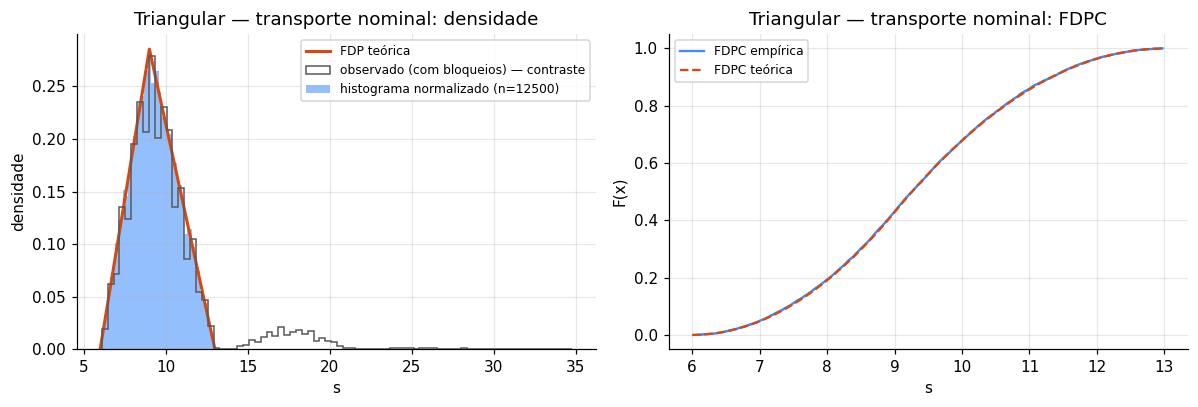

Área do histograma = 1.000000
Kolmogorov–Smirnov: D = 0.0050, p-valor = 0.906


In [6]:
p = samples.template
tri = ba.Triangular(p["TransportMinSeconds"], p["TransportModeSeconds"], p["TransportMaxSeconds"])
print(f"a={tri.a}, c={tri.c}, b={tri.b}:  E[T]=(a+b+c)/3={tri.mean:.4f} s   Var(T)=(a²+b²+c²-ab-ac-bc)/18={tri.var:.4f} s²")
def observed_overlay(ax, grid):
    obs = samples.bags.observed_transport_s.dropna()
    ax.hist(obs[obs < tri.b + 30], bins=80, density=True, histtype="step", color="0.35", label="observado (com bloqueios) — contraste")
moments.append(continuous_validation(samples.bags.nominal_transport_s, tri, "Triangular — transporte nominal", "s",
                                     "va1_triangular", bins=45, value_range=(tri.a, tri.b), extra=observed_overlay))

## 4. VA2 — duração sorteada da inspeção, Exponencial(λI = 1/8 s⁻¹)
Amostra bruta `inspection_s` (sorteada quando a inspeção começa). A duração efetiva no scanner é arredondada ao tick;
por isso valida-se a amostra bruta.

λ=0.12500 s⁻¹:  E[T]=1/λ=8.0000 s   Var(T)=1/λ²=64.0000 s²


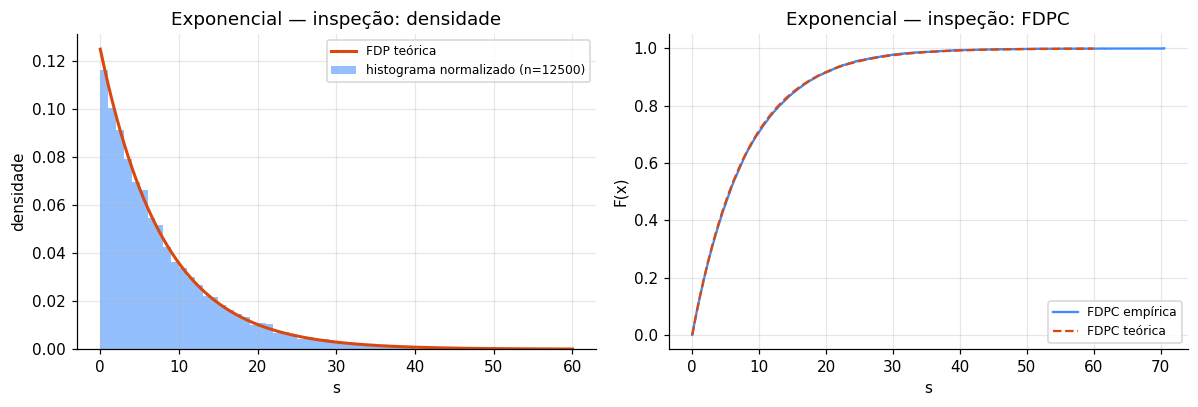

Área do histograma = 1.000000
Kolmogorov–Smirnov: D = 0.0081, p-valor = 0.391


In [7]:
expo = ba.Exponential(1 / p["MeanInspectionSeconds"])
print(f"λ={expo.rate:.5f} s⁻¹:  E[T]=1/λ={expo.mean:.4f} s   Var(T)=1/λ²={expo.var:.4f} s²")
moments.append(continuous_validation(samples.bags.inspection_s, expo, "Exponencial — inspeção", "s",
                                     "va2_exponencial", bins=60, value_range=(0, 60)))

### Inspeção ≠ espera na fila ≠ tempo total
A espera `queue_wait_s = scan_start − queue_enter` e o tempo no sistema `total_s = complete − arrival` resultam da
dinâmica da fila (chegadas a cada 5 s, serviço médio 8 s ⇒ sistema sobrecarregado, ρ = 1,6) e **não** seguem a
Exponencial(1/8). Não são sorteados.

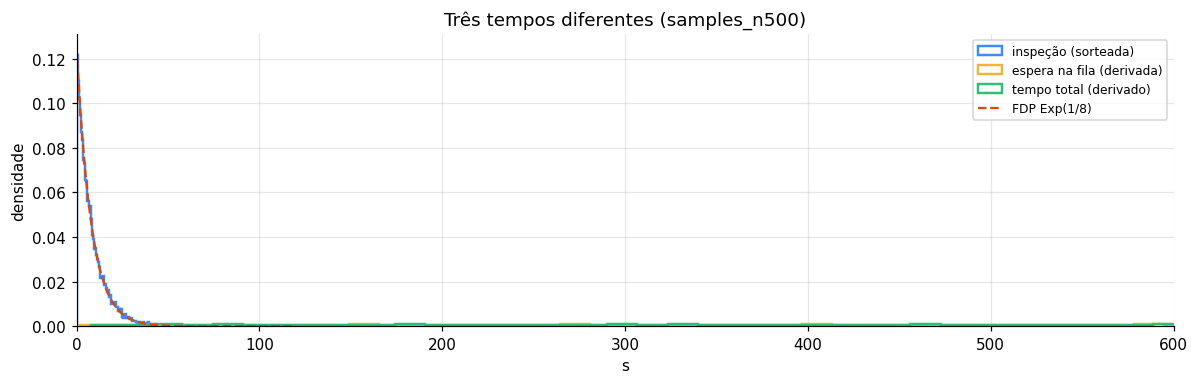

,count,mean,std,min,25%,50%,75%,max
inspection_s,12500.0000,8.0422,7.9016,0.0033,2.3351,5.6417,11.2420,70.5754
queue_wait_s,12500.0000,795.0802,467.4572,0.0000,393.4000,799.4500,1171.5750,1983.5000
total_s,12500.0000,813.4891,467.4193,8.1000,411.0750,816.6000,1187.9750,1999.2000


In [8]:
b = samples.bags
fig, ax = plt.subplots(figsize=(11, 3.6))
for col, lab, c in [("inspection_s", "inspeção (sorteada)", C_EMP), ("queue_wait_s", "espera na fila (derivada)", "#F2B33D"), ("total_s", "tempo total (derivado)", "#2FBF71")]:
    ax.hist(b[col].dropna(), bins=120, density=True, histtype="step", lw=1.6, color=c, label=lab)
grid = np.linspace(0, 120, 400); ax.plot(grid, expo.pdf(grid), color=C_TH, ls="--", label="FDP Exp(1/8)")
ax.set(xlim=(0, 600), xlabel="s", ylabel="densidade", title="Três tempos diferentes (samples_n500)"); ax.legend(fontsize=8)
save(fig, "va2_tempos_distintos")
pd.DataFrame({c: b[c].describe() for c in ["inspection_s", "queue_wait_s", "total_s"]}).T

## 5. VA3 — peso, Normal truncada(μ=18, σ=4, L=5, H=32)
Comparação com a normal **condicionada** a [L, H] (fórmulas de `MATH_MODELS.md`, Φ avaliada com `scipy.special.ndtr`
e, para intervalos na cauda direita, pela função de sobrevivência). A normal não truncada aparece só como contraste.

α=-3.2500, β=3.5000, Z=Φ(β)-Φ(α)=0.99919035
E[W] truncada = 18.004629 kg (μ = 18)   Var(W) truncada = 15.845473 kg² (σ² = 16)
mínimo observado 5.325 kg, máximo 31.835 kg (todos em [L, H])
Massa removida pela truncagem: 1 - Z = 0.00081; por isso a normal original quase coincide com a truncada neste perfil.


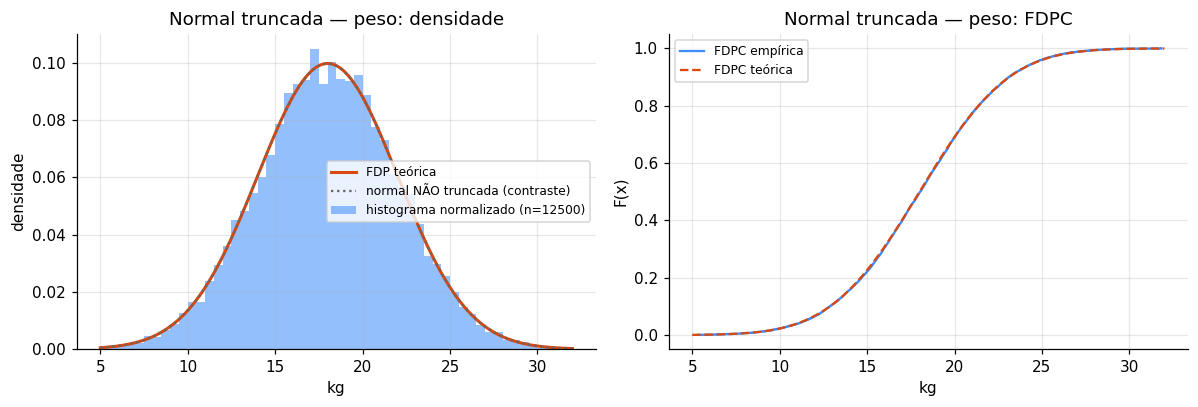

Área do histograma = 1.000000
Kolmogorov–Smirnov: D = 0.0068, p-valor = 0.602


In [9]:
tn = ba.TruncatedNormal(p["WeightBaseMeanKg"], p["WeightBaseStdKg"], p["MinWeightKg"], p["MaxWeightKg"])
print(f"α={tn.alpha:.4f}, β={tn.beta:.4f}, Z=Φ(β)-Φ(α)={tn.z:.8f}")
print(f"E[W] truncada = {tn.mean:.6f} kg (μ = {tn.mu})   Var(W) truncada = {tn.var:.6f} kg² (σ² = {tn.sigma**2})")
def plain_normal(ax, grid):
    ax.plot(grid, np.exp(-0.5 * ((grid - tn.mu) / tn.sigma) ** 2) / (tn.sigma * math.sqrt(2 * math.pi)), color="0.4", ls=":", label="normal NÃO truncada (contraste)")
w = samples.bags.weight_kg
print(f"mínimo observado {w.min():.3f} kg, máximo {w.max():.3f} kg (todos em [L, H])")
print(f"Massa removida pela truncagem: 1 - Z = {1 - tn.z:.5f}; por isso a normal original quase coincide com a truncada neste perfil.")
moments.append(continuous_validation(w, tn, "Normal truncada — peso", "kg", "va3_normal_truncada", bins=54,
                                     value_range=(tn.low, tn.high), extra=plain_normal))

## 6. VA4 — número de malas sinalizadas por execução, Binomial(N=60, p=0,08)
Cada execução completa dá **uma** observação $N_S=\sum_{i=1}^{60} A_i$ (soma das decisões Bernoulli tomadas pelo motor).
Usam-se 2 000 execuções independentes (seeds distintas, N e p fixos). Não há sorteios adicionais de contagens.

2000 execuções; N=60, p=0.08:  E[N_S]=np=4.8000   Var(N_S)=np(1-p)=4.4160


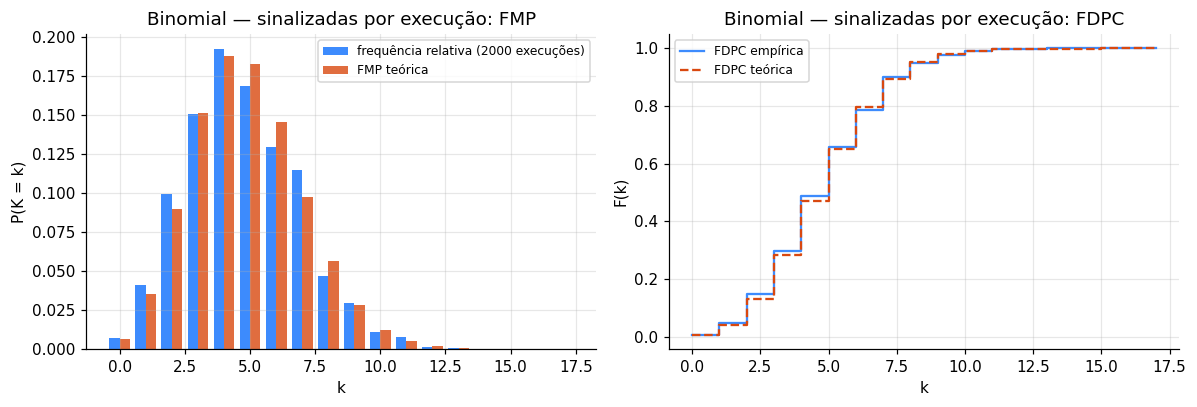

Qui-quadrado (células com esperado ≥ 5): X² = 21.95, gl = 12, p-valor = 0.038
Execução exemplo (seed 42): N_S = 4 — apenas UMA observação da Binomial(60, 0,08).


In [10]:
counts, n, prob = ba.binomial_counts(binom.runs)
print(f"{len(counts)} execuções; N={n}, p={prob}:  E[N_S]=np={n*prob:.4f}   Var(N_S)=np(1-p)={n*prob*(1-prob):.4f}")
discrete_validation(counts, lambda k: ba.binomial_pmf(k, n, prob), "Binomial — sinalizadas por execução", "va4_binomial", "execuções")
moments.append(ba.compare_moments("Binomial — N_S", counts, n * prob, n * prob * (1 - prob)))
print(f"Execução exemplo (seed 42): N_S = {int(example.bags.flagged.sum())} — apenas UMA observação da Binomial(60, 0,08).")

## 7. VA5 — ocorrências de bloqueio, processo de Poisson (λB = 1/120 s⁻¹)
Usam-se os instantes matemáticos `scheduled_time_s` dos eventos `BlockageOccurrence` (incluindo ocorrências durante uma
paragem já ativa). Contagens em janelas **fixas** de T = 120 s em [0, 240 s): com chegadas constantes a última mala chega
aos 295 s, logo **todas** as execuções observam esse horizonte por completo e cada janela tem a mesma exposição.
Não se usa o total de bloqueios por execução (duração variável).

duração mínima das execuções = 330.6 s (≥ 240 s)
T=120 s: 4000 janelas, λT = 1.0000, média = 0.9818, variância = 1.0037
T=60 s: 8000 janelas, λT = 0.5000, média = 0.4909, variância = 0.4960


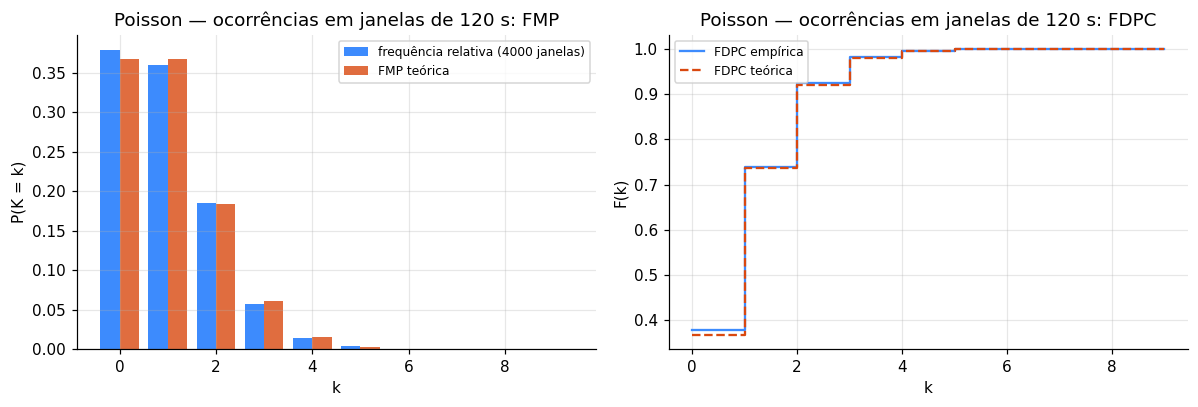

Qui-quadrado (células com esperado ≥ 5): X² = 4.28, gl = 5, p-valor = 0.510


In [11]:
rate = binom.template["BlockageRatePerSecond"]
print(f"duração mínima das execuções = {binom.runs.end_time_s.min():.1f} s (≥ 240 s)")
for T, H in [(120, 240), (60, 240)]:
    w_counts = ba.poisson_window_counts(binom.blockages, binom.runs, T, H)
    print(f"T={T} s: {len(w_counts)} janelas, λT = {rate*T:.4f}, média = {w_counts.mean():.4f}, variância = {w_counts.var(ddof=1):.4f}")
windows = ba.poisson_window_counts(binom.blockages, binom.runs, 120, 240)
discrete_validation(windows, lambda k: ba.poisson_pmf(k, rate * 120), "Poisson — ocorrências em janelas de 120 s", "va5_poisson", "janelas")
moments.append(ba.compare_moments("Poisson — N_B(120 s)", windows, rate * 120, rate * 120))

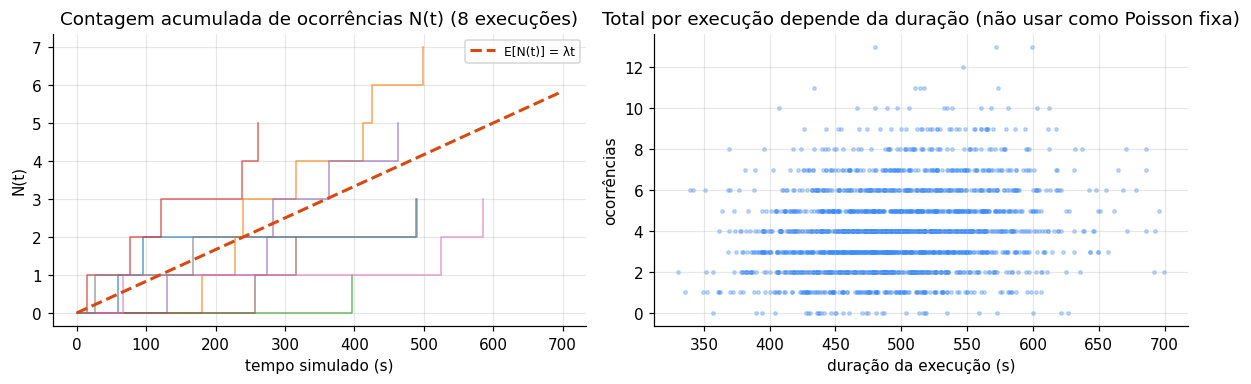

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for seed in binom.runs.seed[:8]:
    t = np.sort(binom.blockages.loc[binom.blockages.seed == seed, "scheduled_time_s"].to_numpy())
    a1.step(np.concatenate([[0], t]), np.arange(len(t) + 1), where="post", lw=1, alpha=0.7)
tt = np.linspace(0, binom.runs.end_time_s.max(), 50); a1.plot(tt, rate * tt, color=C_TH, lw=2, ls="--", label="E[N(t)] = λt")
a1.set(title="Contagem acumulada de ocorrências N(t) (8 execuções)", xlabel="tempo simulado (s)", ylabel="N(t)"); a1.legend(fontsize=8)
a2.scatter(binom.runs.end_time_s, binom.runs.blockage_occurrences, s=5, alpha=0.3, color=C_EMP)
a2.set(title="Total por execução depende da duração (não usar como Poisson fixa)", xlabel="duração da execução (s)", ylabel="ocorrências")
save(fig, "va5_poisson_processo")

### Ocorrências Poisson ≠ inícios de paragem ≠ tempo parado (execução exemplo)
Uma ocorrência durante uma paragem ativa prolonga-a (max(fim, t+d)) mas não cria nova paragem.

In [13]:
ev = example.events
stops = ba.stoppage_intervals(ev)
pd.DataFrame({"ocorrências Poisson (BlockageOccurrence)": [(ev.event_type == "BlockageOccurrence").sum()],
              "inícios de paragem (BlockageStarted)": [(ev.event_type == "BlockageStarted").sum()],
              "duração total das paragens [s]": [float((stops[:, 1] - stops[:, 0]).sum()) if len(stops) else 0.0]})

,ocorrências Poisson (BlockageOccurrence),inícios de paragem (BlockageStarted),duração total das paragens [s]
0,5,5,40.0000


## 8. Resumo — momentos teóricos vs amostrais

In [14]:
summary = pd.DataFrame([m.row() for m in moments]).set_index("variável")
summary

,n,E teórico,média amostral,z(média),Var teórica,variância amostral,z(var)
variável,,,,,,,
Triangular — transporte nominal,12500,9.3333,9.3247,-0.6754,2.0556,2.0657,0.4628
Exponencial — inspeção,12500,8.0000,8.0422,0.5899,64.0000,62.4355,-1.0593
Normal truncada — peso,12500,18.0046,18.0278,0.6521,15.8455,15.7286,-0.6010
Binomial — N_S,2000,4.8000,4.7455,-1.1598,4.4160,4.6230,1.3922
Poisson — N_B(120 s),4000,1.0000,0.9818,-1.1542,1.0000,1.0037,0.1263


In [15]:
print("|z| < 3 em todas as linhas:", bool((summary[["z(média)", "z(var)"]].abs() < 3).all().all()))

|z| < 3 em todas as linhas: True


## 9. Análise operacional
Tudo o que segue é **derivado** dos registos exportados (timestamps discretizados ao tick Δt = 0,1 s), não sorteado.

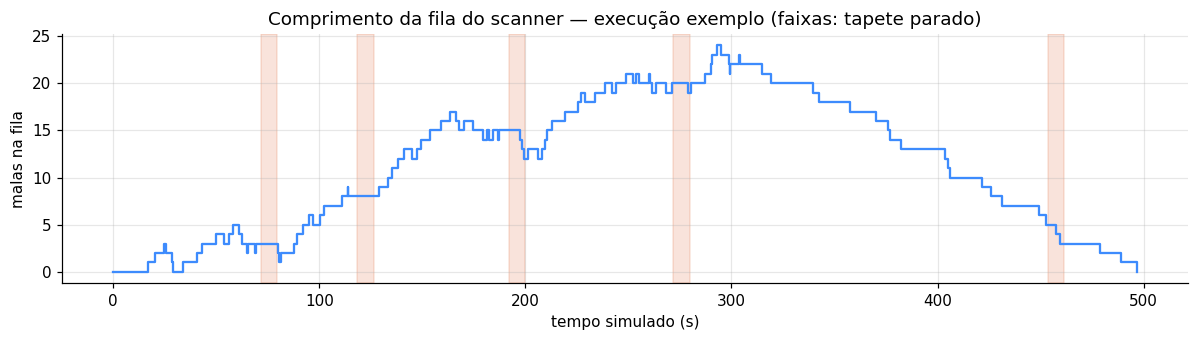

Comprimento médio da fila (média temporal) = 11.36; máximo = 24


In [16]:
times, lengths = ba.queue_length_series(example.events)
end = example.events.time_s.max()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.step(times, lengths, where="post", color=C_EMP)
for s, e in ba.stoppage_intervals(example.events):
    ax.axvspan(s, e, color=C_TH, alpha=0.15)
ax.set(title="Comprimento da fila do scanner — execução exemplo (faixas: tapete parado)", xlabel="tempo simulado (s)", ylabel="malas na fila")
save(fig, "op_fila_exemplo")
print(f"Comprimento médio da fila (média temporal) = {ba.time_average(times, lengths, end):.2f}; máximo = {lengths.max()}")

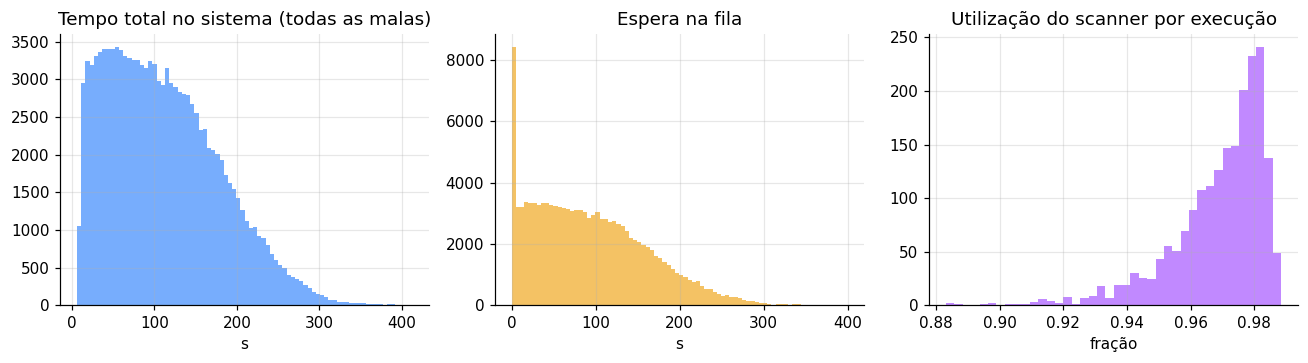

,count,mean,std,min,25%,50%,75%,max
end_time_s,2000.0000,496.7143,59.2684,330.6000,455.0750,494.3500,536.2500,699.4000
approved,2000.0000,55.2545,2.1501,47.0000,54.0000,55.0000,57.0000,60.0000
flagged,2000.0000,4.7455,2.1501,0.0000,3.0000,5.0000,6.0000,13.0000
blockage_occurrences,2000.0000,4.0865,2.0879,0.0000,3.0000,4.0000,5.0000,13.0000
blocked_seconds,2000.0000,31.3835,15.6669,0.0000,21.2000,32.0000,40.0000,94.2000
mean_queue_wait_s,2000.0000,93.2786,32.9992,14.6667,69.9763,90.6825,114.2083,237.3517
mean_total_s,2000.0000,111.5842,33.8512,29.4417,87.8804,109.0242,133.1650,258.7150
scanner_utilization,2000.0000,0.9689,0.0149,0.8831,0.9622,0.9729,0.9798,0.9885


In [17]:
r = binom.runs
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].hist(binom.bags.total_s.dropna(), bins=80, color=C_EMP, alpha=0.7); axs[0].set(title="Tempo total no sistema (todas as malas)", xlabel="s")
axs[1].hist(binom.bags.queue_wait_s.dropna(), bins=80, color="#F2B33D", alpha=0.8); axs[1].set(title="Espera na fila", xlabel="s")
axs[2].hist(r.scanner_utilization, bins=40, color="#B26CFF", alpha=0.8); axs[2].set(title="Utilização do scanner por execução", xlabel="fração")
save(fig, "op_distribuicoes")
r[["end_time_s", "approved", "flagged", "blockage_occurrences", "blocked_seconds", "mean_queue_wait_s", "mean_total_s", "scanner_utilization"]].describe().T

## 10. Comparação de cenários (300–2000 execuções cada)

Médias por execução; EP = erro-padrão da média entre execuções. Diferenças menores que ~2 EP não são distinguíveis.


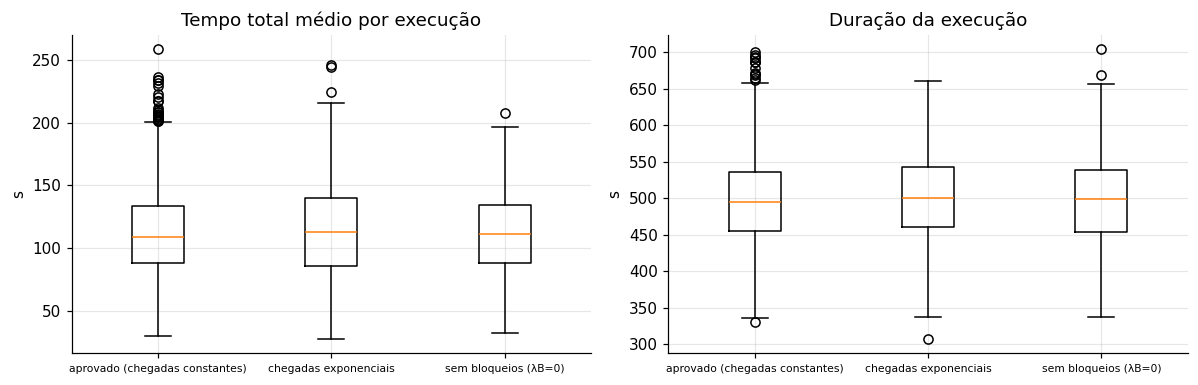

,execuções,espera média [s],EP espera,tempo total médio [s],EP total,utilização,duração [s],tempo bloqueado [s],sinalizadas
aprovado (chegadas constantes),2000,93.2786,0.7379,111.5842,0.7569,0.9689,496.7143,31.3835,4.7455
chegadas exponenciais,300,96.9933,2.2286,115.3886,2.2695,0.9628,503.5893,32.7600,4.8333
sem bloqueios (λB=0),300,94.5528,1.8245,112.0193,1.8759,0.9725,498.7120,0.0000,4.7700


In [18]:
scen = {"aprovado (chegadas constantes)": binom.runs, "chegadas exponenciais": scen_exp.runs, "sem bloqueios (λB=0)": scen_nob.runs}
cols = ["mean_queue_wait_s", "mean_total_s", "scanner_utilization", "end_time_s", "blocked_seconds", "flagged"]
table = pd.DataFrame({name: runs[cols].mean() for name, runs in scen.items()}).T
table.columns = ["espera média [s]", "tempo total médio [s]", "utilização", "duração [s]", "tempo bloqueado [s]", "sinalizadas"]
se = pd.DataFrame({name: runs[cols].std(ddof=1) / math.sqrt(len(runs)) for name, runs in scen.items()}).T
table.insert(1, "EP espera", se["mean_queue_wait_s"]); table.insert(3, "EP total", se["mean_total_s"])
table.insert(0, "execuções", [len(runs) for runs in scen.values()])
print("Médias por execução; EP = erro-padrão da média entre execuções. Diferenças menores que ~2 EP não são distinguíveis.")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].boxplot([runs.mean_total_s for runs in scen.values()], tick_labels=list(scen.keys())); axs[0].set(title="Tempo total médio por execução", ylabel="s")
axs[1].boxplot([runs.end_time_s for runs in scen.values()], tick_labels=list(scen.keys())); axs[1].set(title="Duração da execução", ylabel="s")
for a in axs: a.tick_params(axis="x", labelsize=7)
save(fig, "op_cenarios")
table

## 11. Limitações
* Os parâmetros são **didáticos** (ver `docs/DATA_SOURCES.md`); a validação demonstra que a implementação segue as leis
  escolhidas, não que estas descrevem um aeroporto real.
* Amostras brutas dentro de cada execução vêm do mesmo stream SplitMix64; execuções diferentes usam seeds consecutivas.
  Os testes de ajustamento (KS, qui-quadrado) são indicativos; α não foi corrigido para comparações múltiplas.
* Tempos operacionais estão quantizados a Δt = 0,1 s; só as amostras brutas são comparadas às leis teóricas.
* Poisson: janelas limitadas a [0, 240 s) porque o horizonte comum mínimo das execuções (chegadas constantes) é ≥ 295 s.
  O tempo bloqueado (`blocked_seconds`) é contabilizado por tick pelo motor e difere ligeiramente da soma dos intervalos exatos.
* O comprimento da fila reconstrói-se dos eventos `ScanQueued`/`ScanStarted` (instantes de tick).